In [ ]:
!pip install -q surprise

In [ ]:
!pip install faiss-cpu --no-cache

In [ ]:
!pip install googletrans==4.0.0-rc1

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from ast import literal_eval
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity
import numpy as np
import pandas as pd
from surprise.model_selection import cross_validate, GridSearchCV
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from googletrans import Translator
import re
from collections import Counter
import faiss
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
from ast import literal_eval

In [ ]:
movies_metadata = pd.read_csv('movies_metadata.csv', low_memory=False)
keywords = pd.read_csv('keywords.csv')
credits = pd.read_csv('credits.csv')
ratings = pd.read_csv('ratings.csv')

In [ ]:
movies_metadata.head(2)

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0


In [ ]:
movies_metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 non-null  object 
 3   genres                 45466 non-null  object 
 4   homepage               7782 non-null   object 
 5   id                     45466 non-null  object 
 6   imdb_id                45449 non-null  object 
 7   original_language      45455 non-null  object 
 8   original_title         45466 non-null  object 
 9   overview               44512 non-null  object 
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  object 
 12  production_companies   45463 non-null  object 
 13  production_countries   45463 non-null  object 
 14  release_date           45379 non-null  object 
 15  re

In [ ]:
movies_metadata.isna().sum()

,0
adult,0
belongs_to_collection,40972
budget,0
genres,0
homepage,37684
id,0
imdb_id,17
original_language,11
original_title,0
overview,954


In [ ]:
movies_metadata['adult'].value_counts()

,count
adult,
False,45454
True,9
- Written by Ørnås,1
Rune Balot goes to a casino connected to the October corporation to try to wrap up her case once and for all.,1
Avalanche Sharks tells the story of a bikini contest that turns into a horrifying affair when it is hit by a shark avalanche.,1


In [ ]:
invalid_adult = movies_metadata[
    ~movies_metadata['adult'].astype(str).str.lower().isin(['true', 'false'])
]

invalid_adult

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
19730,- Written by Ørnås,0.065736,/ff9qCepilowshEtG2GYWwzt2bs4.jpg,"[{'name': 'Carousel Productions', 'id': 11176}...","[{'iso_3166_1': 'CA', 'name': 'Canada'}, {'iso...",1997-08-20,0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29503,Rune Balot goes to a casino connected to the ...,1.931659,/zV8bHuSL6WXoD6FWogP9j4x80bL.jpg,"[{'name': 'Aniplex', 'id': 2883}, {'name': 'Go...","[{'iso_3166_1': 'US', 'name': 'United States o...",2012-09-29,0,68.0,"[{'iso_639_1': 'ja', 'name': '日本語'}]",Released,...,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35587,Avalanche Sharks tells the story of a bikini ...,2.185485,/zaSf5OG7V8X8gqFvly88zDdRm46.jpg,"[{'name': 'Odyssey Media', 'id': 17161}, {'nam...","[{'iso_3166_1': 'CA', 'name': 'Canada'}]",2014-01-01,0,82.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,...,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Данные три строки содержат некорректные значения не только в столбце adults, так что удалим их:

In [ ]:
movies_metadata = movies_metadata.drop([19730, 29503, 35587], errors='ignore')

Объединим 3 таблицы в одну:

In [ ]:
movies_metadata['id'] = pd.to_numeric(movies_metadata['id'])
keywords['id'] = pd.to_numeric(keywords['id'])
credits['id'] = pd.to_numeric(credits['id'])

movies = movies_metadata.merge(credits, on='id').merge(keywords, on='id')

In [ ]:
movies.shape

(46628, 27)

In [ ]:
movies['id'] = pd.to_numeric(movies['id'])
movies['popularity'] = pd.to_numeric(movies['popularity'], errors='coerce')

Удалим столбцы imdb_id и poster_path, поскольку они не несут важной информации:

In [ ]:
movies = movies.drop(['imdb_id', 'poster_path'], axis=1)
movies = movies.dropna(subset=['id'])

Заполним пропуски в столбце title словами из original_title, в столбце title позже переведем их на английский язык:

In [ ]:
translator = Translator()

def translate_to_english(text, max_retries=3):
    for attempt in range(max_retries):
            translation = translator.translate(str(text), dest='en')
            return translation.text

In [ ]:
def fill_and_translate_title(row):
    if pd.isna(row['title']) or str(row['title']).strip() == '':
        if pd.notna(row['original_title']):
            return translate_to_english(row['original_title'])
    return row['title']

movies['title'] = movies.apply(fill_and_translate_title, axis=1)

print("Примеры переведенных названий:")
sample = movies[movies['title'] != movies['original_title']].head(5)[['original_title', 'title']]
display(sample)

Примеры переведенных названий:


,original_title,title
28,La Cité des Enfants Perdus,The City of Lost Children
29,摇啊摇，摇到外婆桥,Shanghai Triad
32,"Guillaumet, les ailes du courage",Wings of Courage
57,Il postino,The Postman
58,Le confessionnal,The Confessional


Обработаем пропуски и изменим типы столбцов:

In [ ]:
fill_rules = {
    # Числовые столбцы
    'budget': {'dtype': 'int64', 'fill': 0},
    'popularity': {'dtype': 'float64', 'fill': movies['popularity'].median()},
    'revenue': {'dtype': 'int64', 'fill': 0},
    'runtime': {'dtype': 'float64', 'fill': movies['runtime'].median()},
    'vote_average': {'dtype': 'float64', 'fill': movies['vote_average'].median()},
    'vote_count': {'dtype': 'int64', 'fill': 0},

    # Категориальные столбцы
    'adult': {'dtype': 'int', 'fill': 0},
    'original_language': {'dtype': 'str', 'fill': 'en'},
    'original_title': {'dtype': 'str', 'fill': 'Unknown'},
    'title': {'dtype': 'str', 'fill': 'Unknown'},
    'status': {'dtype': 'str', 'fill': 'Released'},
    'video': {'dtype': 'int', 'fill': 0},

    # Текстовые столбцы
    'overview': {'dtype': 'str', 'fill': 'No overview available'},
    'tagline': {'dtype': 'str', 'fill': ''},
    'homepage': {'dtype': 'str', 'fill': ''},

    # JSON-столбцы
    'belongs_to_collection': {'dtype': 'object', 'fill': '{}'},
    'genres': {'dtype': 'object', 'fill': '[]'},
    'production_companies': {'dtype': 'object', 'fill': '[]'},
    'production_countries': {'dtype': 'object', 'fill': '[]'},
    'spoken_languages': {'dtype': 'object', 'fill': '[]'},

    # Дата
    'release_date': {'dtype': 'datetime64[ns]', 'fill': '1900-01-01'}
}

def process_column(df, col, rules):
    if col in ['adult', 'video']:
        df[col] = df[col].map({'False': 0, 'True': 1})
        df[col] = df[col].fillna(rules['fill']).astype('int64')

    elif rules['dtype'].startswith('datetime'):
        df[col] = pd.to_datetime(df[col], errors='coerce').fillna(pd.to_datetime(rules['fill']))

    else:
        df[col] = df[col].fillna(rules['fill']).astype(rules['dtype'])
    return df

for col, rules in fill_rules.items():
    if col in movies.columns:
        movies = process_column(movies, col, rules)

print("Осталось пропусков после обработки:")
print(movies.isna().sum())

movies.to_csv('movies_metadata_processed.csv', index=False)

Осталось пропусков после обработки:
adult                    0
belongs_to_collection    0
budget                   0
genres                   0
homepage                 0
id                       0
original_language        0
original_title           0
overview                 0
popularity               0
production_companies     0
production_countries     0
release_date             0
revenue                  0
runtime                  0
spoken_languages         0
status                   0
tagline                  0
title                    0
video                    0
vote_average             0
vote_count               0
cast                     0
crew                     0
keywords                 0
dtype: int64


In [ ]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46628 entries, 0 to 46627
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   adult                  46628 non-null  int64         
 1   belongs_to_collection  46628 non-null  object        
 2   budget                 46628 non-null  int64         
 3   genres                 46628 non-null  object        
 4   homepage               46628 non-null  object        
 5   id                     46628 non-null  int64         
 6   original_language      46628 non-null  object        
 7   original_title         46628 non-null  object        
 8   overview               46628 non-null  object        
 9   popularity             46628 non-null  float64       
 10  production_companies   46628 non-null  object        
 11  production_countries   46628 non-null  object        
 12  release_date           46628 non-null  datetime64[ns]
 13  r

In [ ]:
movies.head(3)

,adult,belongs_to_collection,budget,genres,homepage,id,original_language,original_title,overview,popularity,...,spoken_languages,status,tagline,title,video,vote_average,vote_count,cast,crew,keywords
0,0,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",21.946943,...,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,,Toy Story,0,7.7,5415,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...","[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,0,{},65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",,8844,en,Jumanji,When siblings Judy and Peter discover an encha...,17.015539,...,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,0,6.9,2413,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...","[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,0,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",,15602,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,11.712900,...,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,0,6.5,92,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...","[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."


Визуализация распределения оценок:

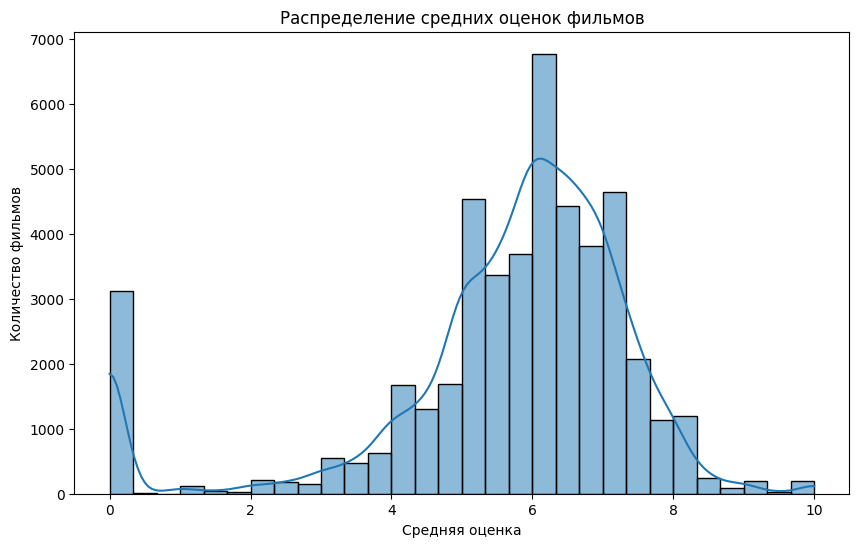

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(movies['vote_average'].dropna(), bins=30, kde=True)
plt.title('Распределение средних оценок фильмов')
plt.xlabel('Средняя оценка')
plt.ylabel('Количество фильмов')
plt.show()

Визуализация распределения жанров:

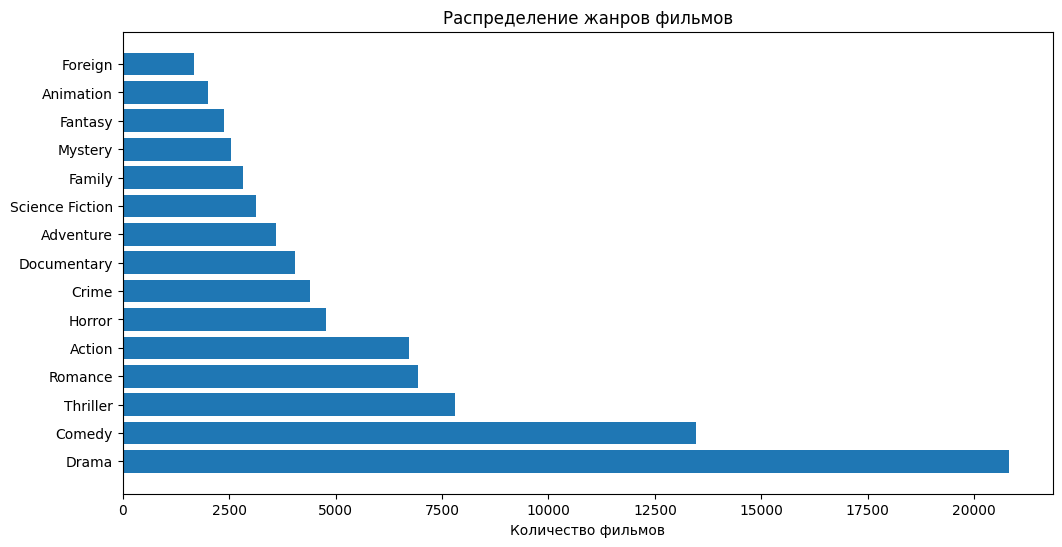

In [ ]:
genres_list = [literal_eval(x) for x in movies['genres'].dropna()]
genres = [genre['name'] for sublist in genres_list for genre in sublist]
genre_counts = Counter(genres).most_common(15)

plt.figure(figsize=(12, 6))
plt.barh([x[0] for x in genre_counts], [x[1] for x in genre_counts])
plt.title('Распределение жанров фильмов')
plt.xlabel('Количество фильмов')
plt.show()

Матрица корреляций:

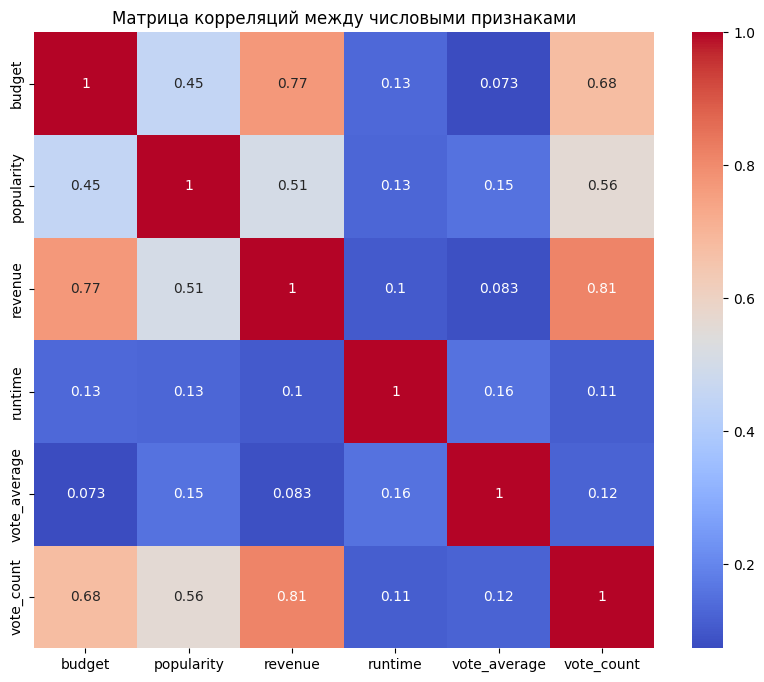

In [ ]:
numeric_cols = ['budget', 'popularity', 'revenue', 'runtime', 'vote_average', 'vote_count']
corr_matrix = movies[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Матрица корреляций между числовыми признаками')
plt.show()

#### **Простая рекомендательная система (на основе популярности)**

Отсортируйте фильмы по рейтингам и популярности и отобразите лучшие фильмы из списка. В качестве дополнительного шага можно ввести аргумент жанра, чтобы получить лучшие фильмы определенного жанра.

In [ ]:
def weighted_rating(x, m, C):
    v = x['vote_count']
    R = x['vote_average']
    return (v/(v+m) * R) + (m/(m+v) * C)

def simple_recommender(df, percentile=0.95, genre=None):
    # Фильтрация по жанру если указан
    if genre:
        df = df[df['genres'].str.contains(genre, na=False)]

    vote_counts = df[df['vote_count'].notnull()]['vote_count'].astype('int')
    vote_averages = df[df['vote_average'].notnull()]['vote_average'].astype('int')
    C = vote_averages.mean()
    m = vote_counts.quantile(percentile)

    # Фильтрация подходящих фильмов
    qualified = df[(df['vote_count'] >= m) & (df['vote_count'].notnull())
                 & (df['vote_average'].notnull())][['title', 'vote_count', 'vote_average', 'popularity']]
    qualified['vote_count'] = qualified['vote_count'].astype('int')
    qualified['vote_average'] = qualified['vote_average'].astype('int')

    # Расчет взвешенного рейтинга
    qualified['wr'] = qualified.apply(weighted_rating, args=(m, C), axis=1)
    qualified = qualified.sort_values('wr', ascending=False)

    return qualified.head(15)

top_movies = simple_recommender(movies)
top_movies.head()

,title,vote_count,vote_average,popularity,wr
15576,Inception,14075,8,29.108149,7.919067
12541,The Dark Knight,12269,8,123.167259,7.907553
23018,Interstellar,11187,8,32.213481,7.898939
2858,Fight Club,9678,8,63.869599,7.883844
4884,The Lord of the Rings: The Fellowship of the Ring,8892,8,32.070725,7.874045


In [ ]:
top = simple_recommender(movies, genre='Animation')
top.head()

,title,vote_count,vote_average,popularity,wr
359,The Lion King,5520,8,21.605761,7.585763
5505,Spirited Away,3968,8,41.048867,7.464227
9746,Howl's Moving Castle,2049,8,16.136048,7.159212
2899,Princess Mononoke,2041,8,17.166725,7.157211
5863,My Neighbor Totoro,1730,8,13.507299,7.071325


#### **Система рекомендаций на основе сходства контента (TF-IDF/CountVectorizer)**

In [ ]:
movies = pd.read_csv('movies_metadata_processed.csv')
movies.isna().sum()

,0
adult,0
belongs_to_collection,0
budget,0
genres,0
homepage,38619
id,0
original_language,0
original_title,0
overview,0
popularity,0


In [ ]:
def get_text_from_json(x, key):
    try:
        data = literal_eval(x)
        return ' '.join([d['name'] for d in data])
    except:
        return ''

movies['genres_str'] = movies['genres'].apply(lambda x: get_text_from_json(x, 'name'))
movies['keywords_str'] = movies['keywords'].apply(lambda x: get_text_from_json(x, 'name'))
movies['combined_text'] = movies['overview'] + ' ' + movies['genres_str'] + ' ' + movies['keywords_str']

In [ ]:
tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
tfdidf_matrix = tfidf.fit_transform(movies['combined_text'])
cosine_sim_tfidf = cosine_similarity(tfdidf_matrix, tfdidf_matrix)

In [ ]:
def get_recommendations(title, cosine_sim=cosine_sim_tfidf, movies_df=movies, top_n=20):
    indices = pd.Series(movies_df.index, index=movies_df['title']).drop_duplicates()

    idx = indices[title]

    sim_scores = list(enumerate(cosine_sim[idx]))

    # Преобразуем numpy arrays в скалярные значения (берем среднее)
    sim_scores = [(i, np.mean(score)) for i, score in sim_scores]

    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:top_n+1]

    movie_indices = [i[0] for i in sim_scores]

    recommendations = movies_df.iloc[movie_indices][['title', 'genres']]
    recommendations['similarity'] = [score for i, score in sim_scores]
    return recommendations.round({'similarity': 3})

In [ ]:
print("Рекомендации для 'The Lord of the Rings: The Fellowship of the Ring':")
recommendations = get_recommendations('The Lord of the Rings: The Fellowship of the Ring', cosine_sim=cosine_sim_tfidf, top_n=10)
recommendations

Рекомендации для 'The Lord of the Rings: The Fellowship of the Ring':


,title,genres,similarity
16456,The Return of the King,"[animation, family, fantasy]",0.322
2019,The Lord of the Rings,"[fantasy, drama, animation]",0.275
31885,Trapped,"[crime, drama, mystery]",0.242
23217,Wolf,"[drama, thriller, crime]",0.240
18495,Magic Christmas Tree,[],0.238
29896,A Fighting Man,[drama],0.222
14229,Airbag,"[comedy, action, crime]",0.216
4231,What's the Worst That Could Happen?,"[action, comedy]",0.213
12846,Borderline,"[crime, drama, thriller]",0.197
25656,The Cop in Blue Jeans,"[drama, action, thriller]",0.197


**Более сложная система рекомендаций, которая будет учитывать жанр, ключевые слова, актерский состав и съемочную группу и т.д.**

1.	Съемочная группа: Из съемочной группы мы выберем только режиссера для нашего полнометражного фильма, поскольку другие не вносят большого вклада в ощущение фильма. Да и все говорят про Кристофера Нолана, а не про оператора)
2.	Актерский состав: С выбором актеров немного сложнее. Менее известные актеры и второстепенные роли на самом деле не влияют на мнение людей о фильме. Поэтому мы должны выбрать только главных героев и соответствующих им актеров. Мы выберем 3 лучших актера, которые указаны в титрах.
Создайте дамп метаданных для каждого фильма, который состоит из жанров, режиссера, главных актеров и ключевых слов Затем используйте векторизатор подсчета для создания матрицы подсчета.

In [ ]:
import pandas as pd
import numpy as np
from ast import literal_eval
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def get_director(x):
    for i in x:
        if i['job'] == 'Director':
            return i['name']
    return np.nan

def get_list(x):
    if isinstance(x, list):
        names = [i['name'] for i in x]
        return names[:3] if len(names) > 3 else names
    return []

movies['director'] = movies['crew'].apply(literal_eval).apply(get_director)
movies['cast'] = movies['cast'].apply(literal_eval).apply(get_list)
movies['keywords'] = movies['keywords'].apply(literal_eval).apply(get_list)
movies['genres'] = movies['genres'].apply(literal_eval).apply(get_list)

In [ ]:
def clean_data(x):
    if isinstance(x, list):
        return [str.lower(i.replace(" ", "")) for i in x]
    else:
        if isinstance(x, str):
            return str.lower(x.replace(" ", ""))
        else:
            return ''

features = ['cast', 'keywords', 'director', 'genres']
for feature in features:
    movies[feature] = movies[feature].apply(clean_data)

In [ ]:
def create_soup(x):
    return ' '.join(x['keywords']) + ' ' + ' '.join(x['cast']) + ' ' + x['director'] + ' ' + ' '.join(x['genres'])

movies['soup'] = movies.apply(create_soup, axis=1)

In [ ]:
tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
tfdidf_matrix = tfidf.fit_transform(movies['soup'])
cosine_sim_tfidf = cosine_similarity(tfdidf_matrix, tfdidf_matrix)

In [ ]:
print("Рекомендации для 'The Lion King':")
recommendations = get_recommendations('The Lion King', cosine_sim=cosine_sim_tfidf, top_n=10)
recommendations

Рекомендации для 'The Lion King':


,title,genres,similarity
651,James and the Giant Peach,"[adventure, animation, family]",0.321
270,Man of the House,"[action, comedy, family]",0.315
1002,Cinderella,"[family, fantasy, animation]",0.314
2238,I'll Be Home for Christmas,"[comedy, family]",0.309
32738,Flashback,"[horror, foreign]",0.304
25191,End of the Road,"[drama, comedy]",0.283
807,The Adventures of Pinocchio,"[animation, family, fantasy]",0.282
42506,The Secret Garden,"[tvmovie, drama, family]",0.280
38367,Annaluise & Anton,[family],0.279
5338,Hey Arnold! The Movie,"[animation, family]",0.277


**Другой вариант этих двух заданий:**

In [ ]:
def get_text_from_json(x, key):
    try:
        data = literal_eval(x)
        return ' '.join([d['name'] for d in data])
    except:
        return ''

movies['genres_str'] = movies['genres'].apply(lambda x: get_text_from_json(x, 'name'))
movies['keywords_str'] = movies['keywords'].apply(lambda x: get_text_from_json(x, 'name'))
movies['combined_text'] = movies['overview'] + ' ' + movies['genres_str'] + ' ' + movies['keywords_str']

def vectorize_with_faiss(text_series, vectorizer):
    sparse_matrix = vectorizer.fit_transform(text_series)

    dense_matrix = sparse_matrix.astype(np.float32).toarray()
    faiss.normalize_L2(dense_matrix)

    dim = dense_matrix.shape[1]
    index = faiss.IndexFlatIP(dim)  # Inner Product = косинусная схожесть

    index.add(dense_matrix)
    return index, vectorizer

tfidf = TfidfVectorizer(stop_words='english', max_features=5000)
count = CountVectorizer(stop_words='english', max_features=5000)

tfidf_index, tfidf_vectorizer = vectorize_with_faiss(movies['combined_text'], tfidf)
count_index, count_vectorizer = vectorize_with_faiss(movies['combined_text'], count)

def recommend_movies_optimized(title, index, vectorizer, movies_df, top_n=5):
    idx = movies_df[movies_df['title'] == title].index[0]

    # Вектор запроса
    query_text = movies_df.loc[idx, 'combined_text']
    query_vec = vectorizer.transform([query_text]).astype(np.float32).toarray()
    faiss.normalize_L2(query_vec)

    # Поиск ближайших соседей
    distances, indices = index.search(query_vec, top_n+1)

    results = indices[0][indices[0] != idx][:top_n]
    return movies_df.iloc[results]['title'].tolist()

film = 'The Dark Knight'
tfidf_lst = recommend_movies_optimized(film, tfidf_index, tfidf_vectorizer, movies)
count_lst = recommend_movies_optimized(film, count_index, count_vectorizer, movies)

In [ ]:
print(f"Рекомендации к фильму {film}:")
print("Рекомендации с TF-IDF (FAISS):")
for i, film in enumerate(tfidf_lst):
  print(i+1, film)

print("\nРекомендации с CountVectorizer (FAISS):")
for i, film in enumerate(count_lst):
  print(i+1, film)

Рекомендации к фильму The Dark Knight:
Рекомендации с TF-IDF (FAISS):
1 The Dark Knight Rises
2 LEGO DC Comics Super Heroes: Batman: Be-Leaguered
3 Batman Begins
4 Batman: Under the Red Hood
5 Batman Returns

Рекомендации с CountVectorizer (FAISS):
1 The Dark Knight Rises
2 Batman Begins
3 Batman: Under the Red Hood
4 Batman & Robin
5 Batman


**Улучшенная система рекомендаций с учетом метаданных**

In [ ]:
# Функция для извлечения имен из JSON
def get_names(x):
    if isinstance(x, str):
        x = literal_eval(x)
    if isinstance(x, list):
        return ' '.join([i['name'].lower().replace(' ', '') for i in x])
    return ''

def get_director(x):
    if isinstance(x, str):
        x = literal_eval(x)
    for i in x:
        if i['job'] == 'Director':
            return i['name'].lower().replace(' ', '')
    return ''

movies['director'] = movies['crew'].apply(get_director)
movies['cast'] = movies['cast'].apply(get_names)
movies['genres'] = movies['genres'].apply(get_names)
movies['keywords'] = movies['keywords'].apply(get_names)

# Увеличение веса режиссера (упоминаем 3 раза)
movies['director'] = movies['director'].apply(lambda x: f"{x} {x} {x}" if x else '')

In [ ]:
def create_metadata(row):
    return f"{row['keywords']} {row['cast']} {row['director']} {row['genres']}"

movies['metadata'] = movies.apply(create_metadata, axis=1)

In [ ]:
tfidf = TfidfVectorizer(stop_words='english', max_features=5000)
count = CountVectorizer(stop_words='english', max_features=5000)

tfidf_index, tfidf_vectorizer = vectorize_with_faiss(movies['metadata'], tfidf)
count_index, count_vectorizer = vectorize_with_faiss(movies['metadata'], count)

In [ ]:
film = 'The Lion King'
tfidf_lst = recommend_movies_optimized(film, tfidf_index, tfidf_vectorizer, movies)
count_lst = recommend_movies_optimized(film, count_index, count_vectorizer, movies)

In [ ]:
print(f"Рекомендации к фильму {film}:")
print("Рекомендации с TF-IDF (FAISS):")
for i, film in enumerate(tfidf_lst):
  print(i+1, film)

print("\nРекомендации с CountVectorizer (FAISS):")
for i, film in enumerate(count_lst):
  print(i+1, film)

Рекомендации к фильму The Lion King:
Рекомендации с TF-IDF (FAISS):
1 St. Louis Blues
2 Hagbard and Signe
3 Soul Power
4 The Tale of the Fox
5 Arthur & Merlin

Рекомендации с CountVectorizer (FAISS):
1 The King and I
2 Hagbard and Signe
3 St. Louis Blues
4 The Tale of the Fox
5 Benji: Off the Leash!


#### **Коллаборативная фильтрация**

In [ ]:
!pip install numpy==1.26.0
!pip install scikit-surprise==1.1.3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.5/58.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 37.1 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 772.0/772.0 kB 8.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.3-cp311-cp311-linux_x86_64.whl size=3311713 sha256=1bafab535a39207b8321404d6104b6aa5c04c76a09f91827b5ae05faa6692268
  Stored in directory: /root/.cache/pip/wheels/f4/2b/26/e2a5eae55d3b7688995e66abe7f40473aac6c95ddd8ee174a8
Successfully built scikit-surprise
  Attempting uninstall: scikit-surprise
    Found existing installation: scikit-surprise 1.1.4
    Uninstalling scikit-surprise-1.1.4:
      Successfully uninstalled scikit-surprise-1.1.4


In [ ]:
from surprise import Dataset, SVD, Reader
from surprise.model_selection import cross_validate, GridSearchCV

In [ ]:
ratings.isna().sum()

,0
userId,0
movieId,0
rating,0
timestamp,0


In [ ]:
ratings.shape

(167409, 4)

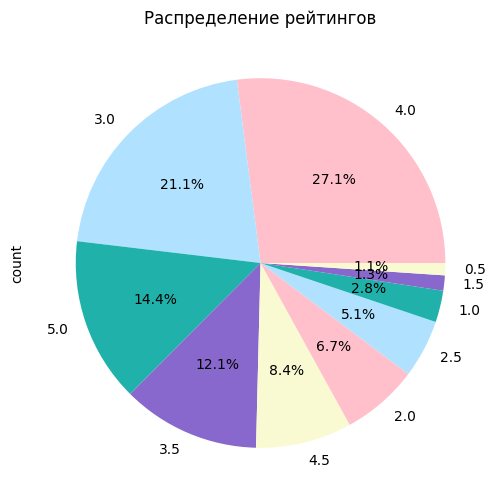

In [ ]:
counts = ratings['rating'].value_counts()

plt.figure(figsize=(8, 6))
counts.plot(kind='pie', autopct='%1.1f%%', colors=['pink', '#B0E2FF', '#20B2AA', '#8968CD', '#FAFAD2'])
plt.title('Распределение рейтингов')
plt.show()

In [ ]:
ratings['rating'].min()

0.5

In [ ]:
reader = Reader(rating_scale=(0.5, 5.0))
data = Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)

In [ ]:
results = cross_validate(SVD(), data, measures=['RMSE', 'MAE'], cv=5, verbose=True)
results

Evaluating RMSE, MAE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.8727  0.8675  0.8667  0.8636  0.8719  0.8685  0.0034  
MAE (testset)     0.6680  0.6669  0.6625  0.6649  0.6690  0.6662  0.0023  
Fit time          3.21    2.70    5.57    5.47    2.35    3.86    1.38    
Test time         0.51    0.37    0.51    0.52    0.31    0.44    0.09    


{'test_rmse': array([0.87274071, 0.86748665, 0.86672652, 0.86361418, 0.87188539]),
 'test_mae': array([0.66801493, 0.66690677, 0.66245429, 0.66491484, 0.6689516 ]),
 'fit_time': (3.2099456787109375,
  2.695521831512451,
  5.571703910827637,
  5.466906547546387,
  2.34968638420105),
 'test_time': (0.5129485130310059,
  0.37218642234802246,
  0.510221004486084,
  0.5233588218688965,
  0.3053154945373535)}

In [ ]:
model = SVD()

In [ ]:
trainset = data.build_full_trainset()
model.fit(trainset)

def predict_rating(userId, movieId):
    return model.predict(userId, movieId).est

print(predict_rating(1, 302))

3.836088496969347
